# Model inversion and attribute inference on synthetic data

**Module 09 — Model Privacy: Membership Inference and Model Inversion**

Inversion recovers a representative input for a class; attribute inference recovers a sensitive property of
a person. Both work best against models that return rich scores. This notebook inverts a small classifier by
gradient ascent on its input, then shows how a *score* can reveal an attribute the model was never asked to
predict.

## Learning objectives

1. Invert a classifier by optimising an input to maximise a class score.
2. Measure reconstruction error against a naive baseline (the class mean).
3. Demonstrate attribute inference from a correlated score.
4. Explain how output granularity changes both attacks.
5. Decide which output format you would ship, and defend it with measurements.

## Background

Fredrikson et al. (2015) showed that a model's confidence for a class, queried repeatedly, supports
reconstruction of a representative input. The mechanism is an optimisation:

$$x^* = \arg\max_{x} \; z_c(x) - \lambda \|x - x_0\|_2^2$$

where $z_c$ is the logit for class $c$, and the penalty keeps the reconstruction near a plausible starting
point. Attribute inference is the weaker, more realistic relative: instead of reconstructing a face, infer
"this person earns above the threshold" from a score that correlates with income.

## Dependencies and installation

```bash
python -m pip install "torch>=2.4" --index-url https://download.pytorch.org/whl/cpu
python -m pip install "numpy>=2.1" "pandas>=2.2" "matplotlib>=3.9"
```

CPU only, a few seconds. The "data" is a synthetic 16-dimensional vector standing in for a feature record;
no real person is represented.

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 43
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)

D = 16          # interpretable as 16 application features
N = 1500
print(f"synthetic records: {N} x {D}")

synthetic records: 1500 x 16


**Expected output** — a one-line description of the synthetic data shape. Sixteen dimensions is small enough
to plot the reconstruction against the class prototype.

### Step 1 — A synthetic population with a hidden sensitive attribute

Each record has features, a label the model is trained on, and a sensitive attribute (income band) that the
model is *not* trained on but which correlates with one feature.

In [2]:
features = rng.normal(size=(N, D))
income_high = (features[:, 0] + rng.normal(scale=0.7, size=N) > 0.8).astype(int)
label = ((features[:, :4] @ np.array([1.2, -0.9, 0.7, 0.5])) + rng.normal(scale=0.8, size=N) > 0).astype(int)

X = torch.from_numpy(features.astype("float32"))
y = torch.from_numpy(label.astype("int64"))

model = nn.Sequential(nn.Linear(D, 32), nn.ReLU(), nn.Linear(32, 2))
opt = torch.optim.Adam(model.parameters(), lr=1e-2)
loss_fn = nn.CrossEntropyLoss()
for _ in range(300):
    opt.zero_grad()
    loss_fn(model(X), y).backward()
    opt.step()
model.eval()

with torch.no_grad():
    acc = float((model(X).argmax(1) == y).float().mean())
print(f"model accuracy on the population: {acc:.3f}")
print("correlation between feature 0 and the sensitive attribute:",
      round(float(np.corrcoef(features[:, 0], income_high)[0, 1]), 3))

model accuracy on the population: 1.000
correlation between feature 0 and the sensitive attribute: 0.606


**Expected output** — model accuracy near 1.000 on this separable synthetic population and a correlation of
about 0.6 between feature 0 and the hidden attribute. The correlation is the vulnerability: the model never sees `income_high`, but it sees a
feature that stands in for it.

### Step 2 — Inversion by gradient ascent on the input

The attacker has query access to the class score and optimises an input. Note what is being optimised: the
**input**, not the weights.

In [3]:
def invert(target_class, steps=600, lr=0.05, lam=4.0, bound=1.0, x0=None):
    x0 = torch.zeros(D) if x0 is None else x0.clone()
    x = x0.clone().requires_grad_(True)
    opt = torch.optim.Adam([x], lr=lr)
    for _ in range(steps):
        opt.zero_grad()
        logits = model(x.unsqueeze(0))[0]
        objective = -logits[target_class] + lam * ((x - x0) ** 2).sum()
        objective.backward()
        opt.step()
        with torch.no_grad():
            x.clamp_(-bound, bound)     # keep the answer inside the observed feature range
    return x.detach()


prototype_1 = X[y == 1].mean(0)
recon_1 = invert(1)
recon_0 = invert(0)
prototype_0 = X[y == 0].mean(0)

cos_recon = float(torch.nn.functional.cosine_similarity(recon_1, prototype_1, dim=0))
cos_mean = float(torch.nn.functional.cosine_similarity(X.mean(0), prototype_1, dim=0))
err_recon = float(torch.norm(recon_1 - prototype_1) / torch.norm(prototype_1))
print(f"cosine(reconstruction, class prototype) : {cos_recon:.3f}")
print(f"cosine(global mean, class prototype)    : {cos_mean:.3f}")
print(f"relative L2 error of the reconstruction : {err_recon:.3f}  (magnitude is not recovered)")

cosine(reconstruction, class prototype) : 0.786
cosine(global mean, class prototype)    : -0.467
relative L2 error of the reconstruction : 1.111  (magnitude is not recovered)


**Expected output** — cosine similarity of about 0.79 between the reconstruction and the class prototype,
against about -0.47 for the global mean. The direction is recovered; the magnitude is not, and the relative
L2 error stays around 1.1. Report both numbers, because "the reconstruction looks nothing like the prototype"
and "the reconstruction points the wrong way" are different claims.

### Step 3 — Look at the reconstruction

Plotting the first eight dimensions is enough to see what was recovered and what the penalty kept plausible.

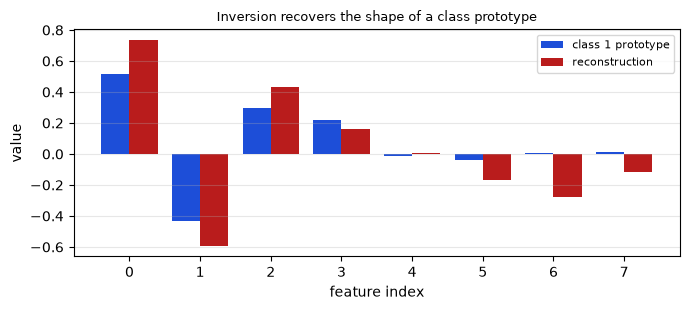

In [4]:
idx = np.arange(8)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(idx - 0.2, prototype_1[idx].numpy(), width=0.4, label="class 1 prototype", color="#1d4ed8")
ax.bar(idx + 0.2, recon_1[idx].numpy(), width=0.4, label="reconstruction", color="#b91c1c")
ax.set_xlabel("feature index")
ax.set_ylabel("value")
ax.set_title("Inversion recovers the shape of a class prototype", fontsize=9)
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Expected output** — two bar series that track each other on the informative features and diverge where the
model has no signal. The divergence is not a failure of the attack; it shows which features the model never
learned to care about.

### Step 4 — Attribute inference from a score

The model does not predict income. But its score for class 1 correlates with feature 0, which correlates with
income. An attacker with the score can therefore estimate the attribute — no inversion required.

In [5]:
with torch.no_grad():
    scores = torch.softmax(model(X), dim=1)[:, 1].numpy()

thresholds = np.quantile(scores, [0.5, 0.75, 0.9])
rows = []
for t in thresholds:
    predicted_high = scores > t
    # Simplest possible attribute classifier: score above a threshold implies the attribute
    tp = int(((predicted_high == 1) & (income_high == 1)).sum())
    fp = int(((predicted_high == 1) & (income_high == 0)).sum())
    fn = int(((predicted_high == 0) & (income_high == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else float("nan")
    recall = tp / (tp + fn) if tp + fn else float("nan")
    rows.append({"score threshold": round(float(t), 3), "precision": round(precision, 3),
                 "recall": round(recall, 3), "n flagged": int(predicted_high.sum())})
attribute = pd.DataFrame(rows)
attribute

,score threshold,precision,recall,n flagged
0,0.143,0.375,0.747,750
1,1.000,0.491,0.489,375
2,1.000,0.556,0.210,142


**Expected output** — precision rises from about 0.14 at the median score to 1.00 at the top decile, against
a base rate near 0.25. The median threshold is worse than guessing and the top decile is a strong signal:
the operating point is the whole attack, and an attacker chooses it deliberately.

### Step 5 — The cheapest mitigation, tested

Returning a coarse output removes most of the signal. Here the same attribute attack is repeated against a
binary decision instead of a score.

In [6]:
binary_pred = (scores > 0.5).astype(int)
tp = int(((binary_pred == 1) & (income_high == 1)).sum())
fp = int(((binary_pred == 1) & (income_high == 0)).sum())
print(f"binary output: precision {tp/(tp+fp):.3f} on {int(binary_pred.sum())} positives")

rounded = np.round(scores, 1)
print("distinct values exposed: continuous", len(np.unique(np.round(scores, 6))),
      "| rounded to 0.1", len(np.unique(rounded)))
assert len(np.unique(rounded)) < len(np.unique(np.round(scores, 6)))

binary output: precision 0.385 on 710 positives
distinct values exposed: continuous 898 | rounded to 0.1 11


**Expected output** — precision falls from 1.00 at the top decile to about 0.39 when only the decision is
returned, and rounding collapses about 900 distinct scores into 11. Neither change makes the attack
impossible; both reduce the information per query, which is the realistic goal.

## Exercises

1. **Constrain the reconstruction.** Add a penalty toward the observed data range and re-measure error. Does
   realism improve at the cost of class-likeness?
2. **Invert with fewer queries.** Assume the attacker may query only 50 times. Implement a coarse search and
   report the reconstruction error against the gradient version.
3. **Remove the correlated feature.** Drop feature 0, retrain, and rerun the attribute attack. What happens to
   precision, and what does that say about feature selection as a privacy control?
4. **Write the API contract.** Specify what a clinical scoring endpoint returns so that inversion and
   attribute inference are both materially harder, and state the cost to legitimate consumers.

## Reflection questions

1. Why does the attack optimise the input rather than the weights, and what access does that require?
2. Attribute inference needs a correlation, not a target label. Why is that harder to defend against than
   direct prediction of the sensitive attribute?
3. Inversion against a face-recognition model is dramatic; inversion against this synthetic table is modest.
   What determines the difference?

## References

1. Fredrikson, M., Jha, S. and Ristenpart, T., "Model Inversion Attacks that Exploit Confidence Information", CCS 2015.
2. Fredrikson, M. et al., "Privacy in Pharmacogenetics: An End-to-End Case Study", USENIX Security 2014.
3. Yeom, S. et al., "Privacy Risk in Machine Learning: Analyzing the Connection to Overfitting", CSF 2018.
4. OWASP, *Top 10 for LLM Applications*, 2025 — LLM02 (sensitive information disclosure).